# Pittsburgh Neighborhood Safety Analysis
### Individual Submetric: Reported Police Incidents

Team name: The Avocado "Pitts"

## Introduction

For my part of the group project, I am measuring neighborhood safety by comparing the number of police reports in each Pittsburgh neighborhood. I chose this submetric because public safety is an important part of neighborhood quality.

My goal is to find which neighborhood had the fewest reported incidents in 2024 and 2025. I will count reports by neighborhood, rank the neighborhoods, and create graphs to show the results.

This is one way to define the “best” neighborhood. It does not prove that a neighborhood is objectively the safest. Neighborhoods have different population sizes and levels of activity, and not every incident is necessarily reported to police.

## The Metric and Dataset

My submetric is **the number of unique police report numbers in each neighborhood** during 2024 and 2025.

- Fewer unique reports means a higher ranking for this submetric.
- I use 2024 and 2025 because they are complete calendar years in the CSV file.
- I remove records that do not have a neighborhood or report number.
- Some report numbers appear on more than one row because one report can contain more than one offense entry. I count each report number only once per neighborhood so that these reports are not counted multiple times.

**Dataset:** Monthly Criminal Activity, from the Western Pennsylvania Regional Data Center (WPRDC).

**Source:** [WPRDC – Monthly Criminal Activity](https://data.wprdc.org/dataset/monthly-criminal-activity-dashboard)

The CSV file used for this notebook is named `CrimeRates.csv`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the CSV dataset
df = pd.read_csv("CrimeRates.csv", low_memory=False)

# Display the first five rows
df.head()

,_id,Report_Number,ReportedDate,ReportedTime,Hour,DayofWeek,ReportedMonth,ReportedYear,NIBRS_Coded_Offense,NIBRS_Offense_Code,...,NIBRS_Offense_Type,NIBRS_Crime_Against,NIBRS_Offense_Grouping,Violation,XCOORD,YCOORD,Zone,Tract,Neighborhood,Block_Address
0,1,PGHP24000024,2024-01-01,00:31,0,Monday,Jan,2024,13A AGGRAVATED ASSAULT,13A,...,Aggravated Assault,Person,A,18 2718 A1 Strangulation Basic - Applying,-80.0268,40.3964,Zone 6,1919,Brookline,"2800 BLOCK OF FITZHUGH WAY PITTSBURGH, PA"
1,2,PGHP24000024,2024-01-01,00:31,0,Monday,Jan,2024,13C INTIMIDATION,13C,...,Intimidation,Person,A,18 2706 A1 Terroristic Threats-General,-80.0268,40.3964,Zone 6,1919,Brookline,"2800 BLOCK OF FITZHUGH WAY PITTSBURGH, PA"
2,3,PGHP24000024,2024-01-01,00:31,0,Monday,Jan,2024,90Z ALL OTHER OFFENSES,90Z,...,All other Offenses,Group B,B,75 3733 A Fleeing or Attempting To Elude Polic...,-80.0268,40.3964,Zone 6,1919,Brookline,"2800 BLOCK OF FITZHUGH WAY PITTSBURGH, PA"
3,4,PGHP24000024,2024-01-01,00:31,0,Monday,Jan,2024,23H ALL OTHER LARCENY,23H,...,All Other Larceny,Property,A,18 3921 A Theft by Unlawful Taking-Movable – L...,-80.0268,40.3964,Zone 6,1919,Brookline,"2800 BLOCK OF FITZHUGH WAY PITTSBURGH, PA"
4,5,PGHP24000017,2024-01-01,00:21,0,Monday,Jan,2024,9999 Vehicle Offense (Not NIBRS Reportable),999,...,Not NIBRS Reportable,Group B,B,LO 6 101 Discharge of Firearms Prohibited,-80.0243,40.4582,Zone 1,2107,Manchester,"1200 BLOCK OF COLUMBUS AVE PITTSBURGH, PA"


## 1. Explore the dataset

First, I check how many rows and columns are in the dataset. I also check which years are included and look at the column names.

In [2]:
# Show the number of rows and columns
print("Dataset size:", df.shape)

# Show all column names
print("Column names:")
print(df.columns)

# Show how many records are listed for each year
print("Records by year:")
print(df["ReportedYear"].value_counts().sort_index())

# Show the first and last reported dates
print("First reported date:", df["ReportedDate"].min())
print("Last reported date:", df["ReportedDate"].max())

Dataset size: (116730, 21)
Column names:
Index(['_id', 'Report_Number', 'ReportedDate', 'ReportedTime', 'Hour',
       'DayofWeek', 'ReportedMonth', 'ReportedYear', 'NIBRS_Coded_Offense',
       'NIBRS_Offense_Code', 'NIBRS_Offense_Category', 'NIBRS_Offense_Type',
       'NIBRS_Crime_Against', 'NIBRS_Offense_Grouping', 'Violation', 'XCOORD',
       'YCOORD', 'Zone', 'Tract', 'Neighborhood', 'Block_Address'],
      dtype='object')
Records by year:
ReportedYear
2024    38750
2025    40956
2026    37024
Name: count, dtype: int64
First reported date: 2024-01-01
Last reported date: 2026-10-31


## 2. Clean the data

I only need the neighborhood, report number, and year columns for my main metric. I remove rows that are missing a neighborhood or report number.

I also standardize one neighborhood name that appears with a different dash character in the CSV. This prevents the same neighborhood from being treated as two separate neighborhoods.

In [3]:
# Remove extra spaces from neighborhood names
df["Neighborhood"] = df["Neighborhood"].str.strip()

# Change the longer dash to a regular hyphen in neighborhood names
df["Neighborhood"] = df["Neighborhood"].str.replace("–", "-", regex=False)

# Remove rows that do not have a neighborhood or report number
df = df.dropna(subset=["Neighborhood", "Report_Number"])

# Keep reports from 2024 and 2025
analysis_df = df[(df["ReportedYear"] == 2024) | (df["ReportedYear"] == 2025)].copy()

# Keep each report number only once in each neighborhood
analysis_df = analysis_df.drop_duplicates(subset=["Report_Number", "Neighborhood"])

print("Rows used in the analysis:", len(analysis_df))
print("Neighborhoods included:", analysis_df["Neighborhood"].nunique())

Rows used in the analysis: 52138
Neighborhoods included: 90


## 3. Count reports by neighborhood

Next, I count the number of unique report numbers in each neighborhood. I sort the results from the fewest reports to the most reports. The neighborhood at the top has the lowest count for this submetric.

In [4]:
# Count reports in each neighborhood
neighborhood_counts = analysis_df.groupby("Neighborhood").size()

# Sort from the fewest reports to the most reports
neighborhood_counts = neighborhood_counts.sort_values()

# Turn the results into a table
neighborhood_ranking = neighborhood_counts.reset_index()
neighborhood_ranking.columns = ["Neighborhood", "Number of Reports"]

# Add a ranking column
neighborhood_ranking["Rank"] = range(1, len(neighborhood_ranking) + 1)

# Display the 15 neighborhoods with the fewest reports
neighborhood_ranking.head(15)

,Neighborhood,Number of Reports,Rank
0,St. Clair,18,1
1,Ridgemont,34,2
2,New Homestead,41,3
3,Chartiers City,47,4
4,East Carnegie,58,5
5,Swisshelm Park,60,6
6,Summer Hill,62,7
7,Esplen,77,8
8,Hays,87,9
9,Fairywood,87,10


## 4. Graph the 15 neighborhoods with the fewest reports

This bar graph makes it easier to compare the neighborhoods with the lowest report counts.

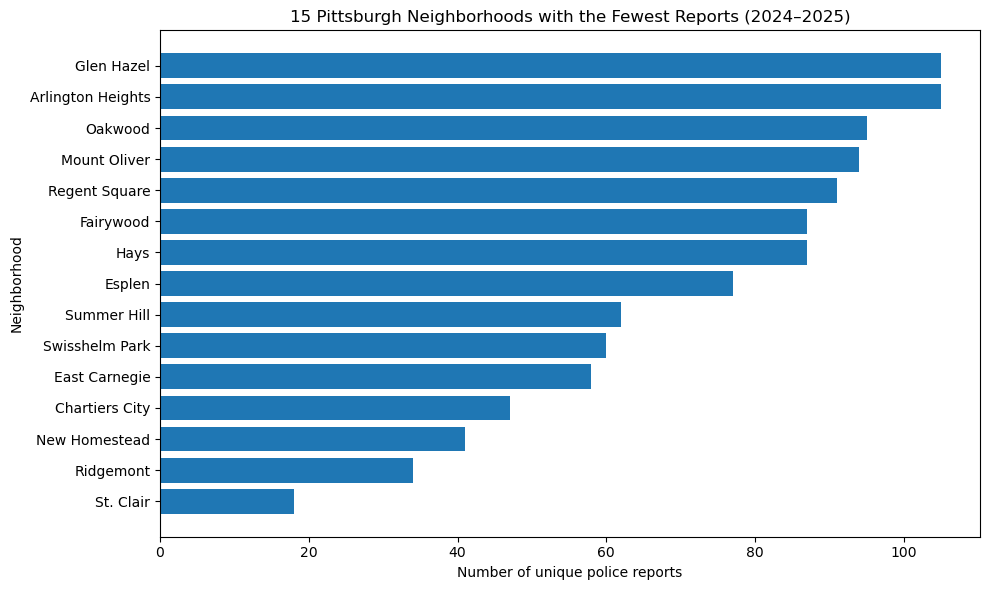

In [5]:
# Get the first 15 neighborhoods in the ranking
lowest_15 = neighborhood_ranking.head(15)

# Make a bar graph
plt.figure(figsize=(10, 6))
plt.barh(lowest_15["Neighborhood"], lowest_15["Number of Reports"])

plt.xlabel("Number of unique police reports")
plt.ylabel("Neighborhood")
plt.title("15 Pittsburgh Neighborhoods with the Fewest Reports (2024–2025)")

plt.tight_layout()
plt.show()

## 5. Find the top neighborhood

The first neighborhood in the ranking has the fewest reported incidents in this analysis. The next cell displays the result.

In [6]:
# Get the first neighborhood in the ranking
best_neighborhood = neighborhood_ranking.iloc[0]

print("Top neighborhood for my safety submetric:", best_neighborhood["Neighborhood"])
print("Number of unique reports:", best_neighborhood["Number of Reports"])
print("Rank:", best_neighborhood["Rank"])

# Display the five neighborhoods with the fewest reports
neighborhood_ranking.head(5)

Top neighborhood for my safety submetric: St. Clair
Number of unique reports: 18
Rank: 1


,Neighborhood,Number of Reports,Rank
0,St. Clair,18,1
1,Ridgemont,34,2
2,New Homestead,41,3
3,Chartiers City,47,4
4,East Carnegie,58,5


## 6. Compare the types of reported offenses

The dataset also includes offense categories. This graph shows the most common offense categories in 2024 and 2025.

These category totals count offense entries in the dataset. A report can have more than one offense entry, so these totals are not the same as the unique report counts used for the neighborhood ranking.

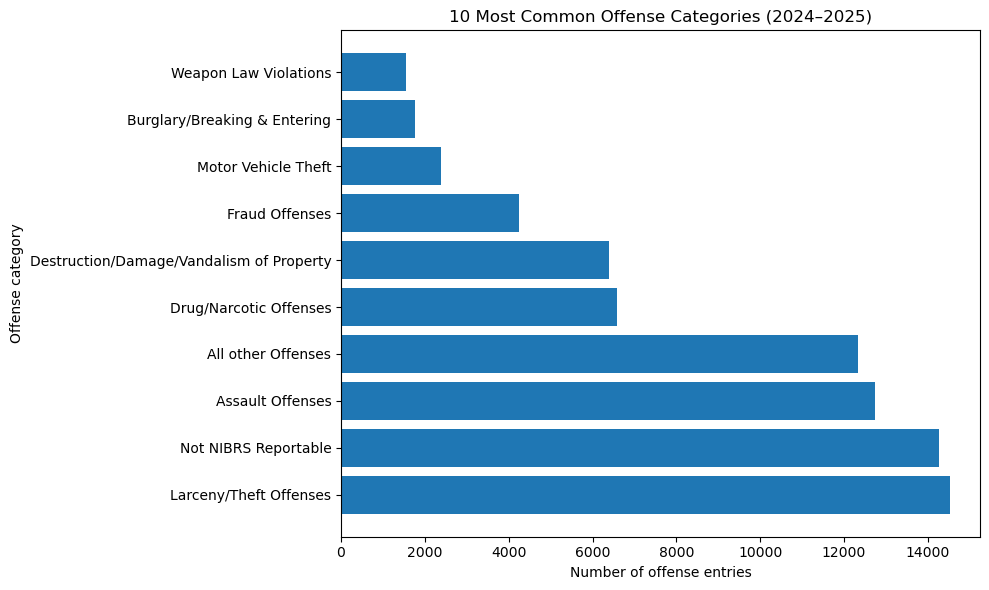

In [7]:
# Keep the 2024 and 2025 records
category_data = df[(df["ReportedYear"] == 2024) | (df["ReportedYear"] == 2025)]

# Count the entries in each offense category
category_counts = category_data["NIBRS_Offense_Category"].value_counts().head(10)

# Make a bar graph
plt.figure(figsize=(10, 6))
plt.barh(category_counts.index, category_counts.values)

plt.xlabel("Number of offense entries")
plt.ylabel("Offense category")
plt.title("10 Most Common Offense Categories (2024–2025)")

plt.tight_layout()
plt.show()

## 7. Compare the top neighborhoods by year

This section compares the yearly report counts for the 10 neighborhoods with the fewest reports across both years. This helps show whether the counts were similar in 2024 and 2025.

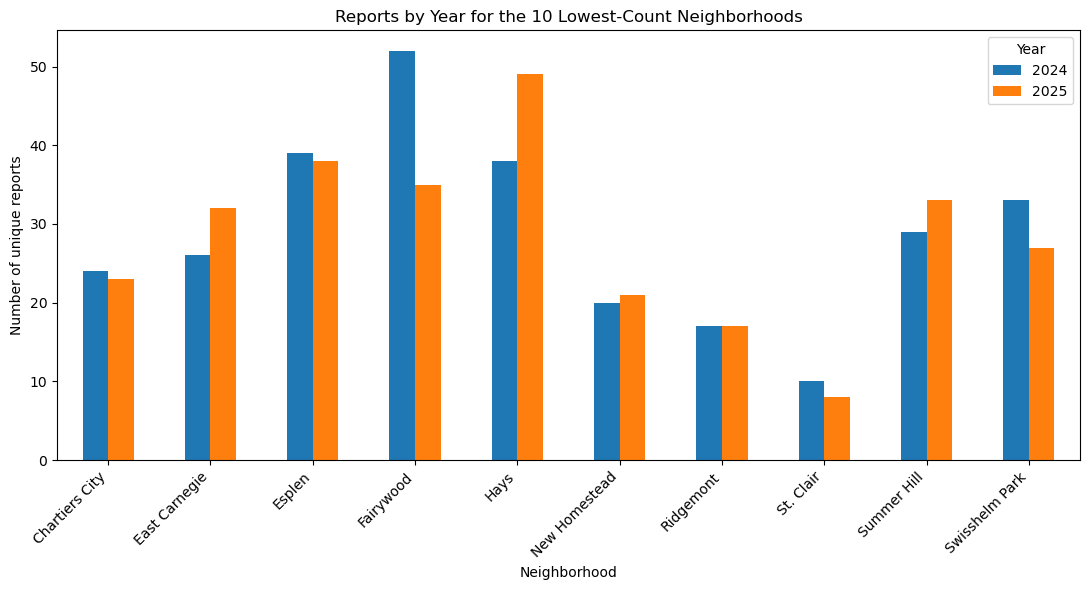

In [8]:
# Get the names of the 10 neighborhoods with the fewest reports
top_10 = neighborhood_ranking.head(10)["Neighborhood"]

# Keep only those neighborhoods
top_10_data = analysis_df[analysis_df["Neighborhood"].isin(top_10)]

# Count reports for each neighborhood in each year
yearly_counts = top_10_data.groupby(["Neighborhood", "ReportedYear"]).size().unstack(fill_value=0)

# Make a bar graph
yearly_counts.plot(kind="bar", figsize=(11, 6))

plt.xlabel("Neighborhood")
plt.ylabel("Number of unique reports")
plt.title("Reports by Year for the 10 Lowest-Count Neighborhoods")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Year")

plt.tight_layout()
plt.show()

## 8. Results and limitations

In this dataset, **St. Clair** has the fewest unique police reports among the Pittsburgh neighborhoods in the 2024–2025 comparison, with **18 reports**. It ranks first for my safety submetric.

There are some exceptions to this result:

1. **Population size:** The dataset does not include neighborhood population. A neighborhood with fewer residents may have fewer reports due to the fact that fewer people live there.
2. **Visitors:** Some neighborhoods have more visitors, businesses, or nightlife than others. This can affect the number of reports.
3. **Reporting:** This dataset contains police reports, not every incident that happens in a neighborhood may be reported.
4. **Multiple offense entries:** One report can include multiple offense entries. I counted each report number once per neighborhood for the main ranking.
5. **Time period:** This comparison only uses 2024 and 2025. The results could be different over a longer period.

For these reasons, I describe St. Clair as the neighborhood with the fewest reported police incidents in this dataset and time period.

## Conclusion

For my individual part of the project, I used reported police activity as a way to measure neighborhood safety. Based on the 2024 and 2025 data, **St. Clair** ranked first because it had the fewest unique police reports, with 18.

I think this is a useful measure because safety is an important part of a neighborhood. However, the number of reports does not tell the whole story. Population size, visitors, and reporting differences can affect the results.
